In [1]:
from __future__ import print_function
import os
import sys
import matplotlib.pyplot as plt
import pandas as pd
from datetime import date
import numpy as np
today = date.today()

prior = 0.041

In [79]:
##########################################################
## This script combines all the STRING's channels subscores
## into the final combined STRING score.
## It uses unpacked protein.links.full.xx.txt.gz as input
## which can be downloaded from the download subpage:
##      https://string-db.org/cgi/download.pl
##########################################################
 
input_file = "../data/9606.protein.links.full.v11.5.txt"

if not os.path.exists(input_file):
    sys.exit("Can't locate input file %s" % input_file)

prior = 0.041

def compute_prior_away(score, prior):

    if score < prior: score = prior
    score_no_prior = (score - prior) / (1 - prior)

    return score_no_prior

s1_neighborhood = []
s1_neighborhood_transferred = []
s1_fusion = []
s1_cooccurrence = []
s1_coexpression = []
s1_coexpression_transferred = []
s1_experiments = []
s1_experiments_transferred = []
s1_database = []
s1_database_transferred = []
s1_textmining = []
s1_textmining_transferred = []


homologies = []

protein1_list = []
protein2_list = []

# Columns = Product
step4 = []

# Columns = 1-Product with prior multiplication
step5 = []


header = True
for line in open(input_file):

    if header:
        header = False
        continue
    
    l = line.split()
    
    ## load the line
        
    (protein1, protein2,
     neighborhood, neighborhood_transferred,
     fusion, cooccurrence,
     homology,
     coexpression, coexpression_transferred,
     experiments, experiments_transferred,
     database, database_transferred,
     textmining, textmining_transferred,
     initial_combined) = l

    homologies.append(float(homology)/1000)


In [103]:
step1 = pd.read_pickle('../output/STRING-step1.pkl')
step2 = pd.read_pickle('../output/STRING-step2.pkl')
step3 = pd.read_pickle('../output/STRING-step3.pkl')

## STEP 1

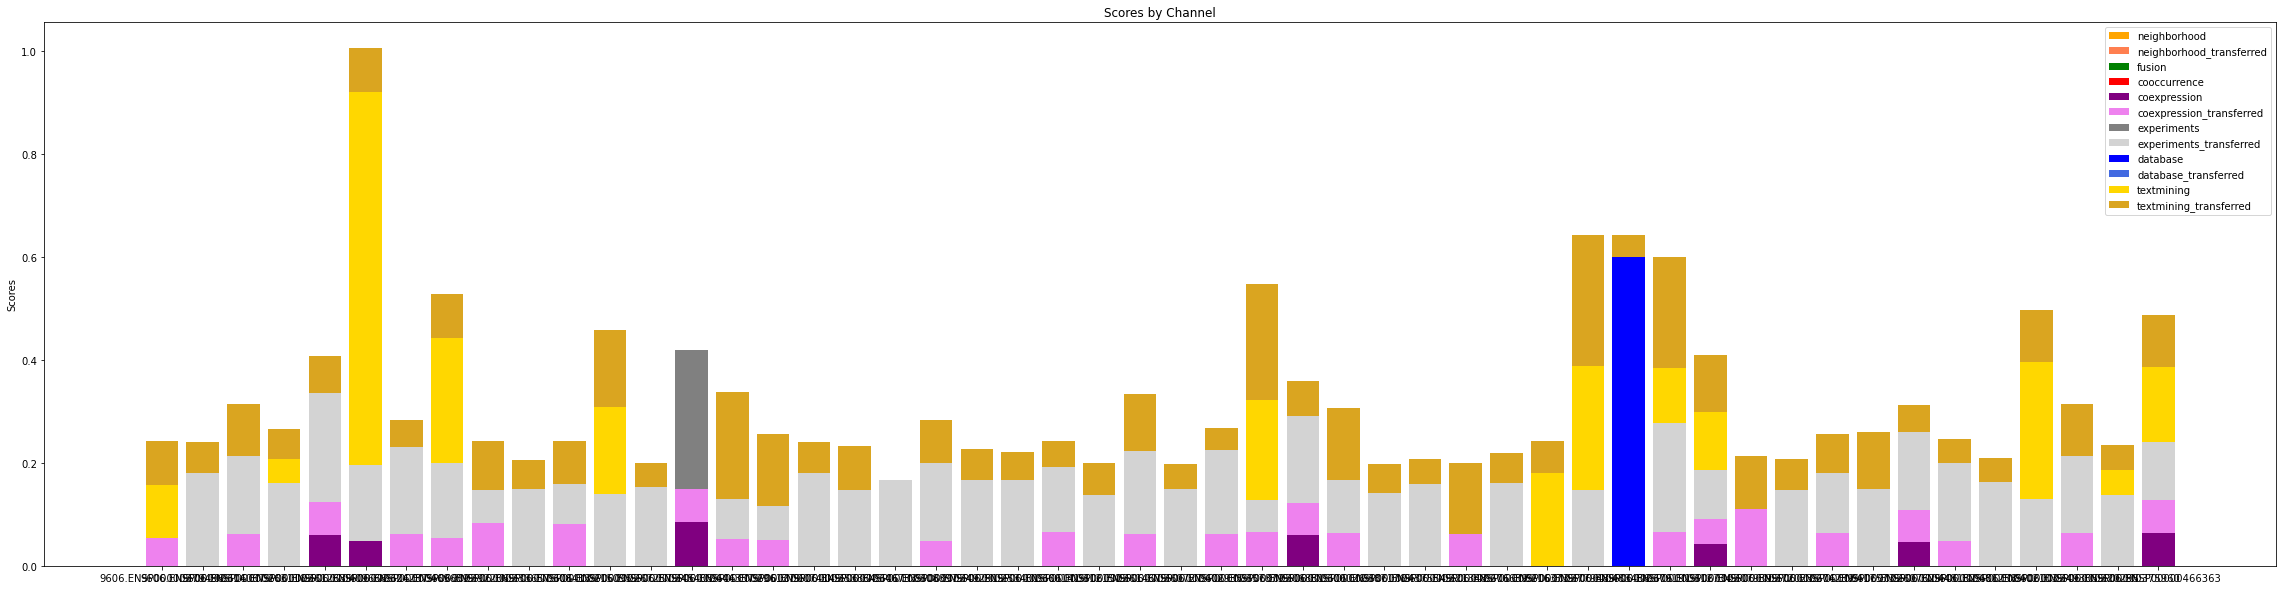

In [104]:
from datetime import date
today = date.today()

colors = ['', '', 'orange', 'coral', 'green', 'red', 'purple', 'violet', 'grey', 'lightgrey', 'blue', 'royalblue', 'gold', 'goldenrod']


width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = step1.protein2.iloc[:50]

bottom_sum = []

for i, c in enumerate(step1.columns.tolist()):
    if i == 2:
        ax.bar(labels, step1[c].iloc[:50], width, label = c, color = colors[i])
        bottom_sum = step1[c].iloc[:50]
    elif i > 2:
        ax.bar(labels, step1[c].iloc[:50], width, label = c, bottom = bottom_sum, color = colors[i])
        bottom_sum = bottom_sum + step1[c].iloc[:50]

ax.set_ylabel('Scores')
ax.set_title('Scores by Channel')
ax.legend()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_step1-first50-associations.png')

In [32]:
step1 = pd.DataFrame({'protein1': protein1_list, 'protein2': protein2_list, 'neighborhood': s1_neighborhood, 
                      'neighborhood_transferred': s1_neighborhood_transferred, 'fusion': s1_fusion, 
                      'cooccurrence': s1_cooccurrence, 'coexpression': s1_coexpression, 
                      'coexpression_transferred': s1_coexpression_transferred, 'experiments': s1_experiments, 
                      'experiments_transferred': s1_experiments_transferred, 'database': s1_database, 
                      'database_transferred': s1_database_transferred, 'textmining': s1_textmining, 
                      'textmining_transferred': s1_textmining_transferred})

## STEP 2

In [40]:
s2_neighborhood = []
s2_neighborhood_transferred = []
s2_fusion = []
s2_cooccurrence = []
s2_coexpression = []
s2_coexpression_transferred = []
s2_experiments = []
s2_experiments_transferred = []
s2_database = []
s2_database_transferred = []
s2_textmining = []
s2_textmining_transferred = []


for i in range(11938498):
    neighborhood_prior_corrected                 = compute_prior_away (s1_neighborhood[i], prior)             
    neighborhood_transferred_prior_corrected     = compute_prior_away (s1_neighborhood_transferred[i], prior) 
    fusion_prior_corrected                       = compute_prior_away (s1_fusion[i], prior)             
    cooccurrence_prior_corrected                 = compute_prior_away (s1_cooccurrence[i], prior)           
    coexpression_prior_corrected                 = compute_prior_away (s1_coexpression[i], prior)            
    coexpression_transferred_prior_corrected     = compute_prior_away (s1_coexpression_transferred[i], prior) 
    experiments_prior_corrected                  = compute_prior_away (s1_experiments[i], prior)   
    experiments_transferred_prior_corrected      = compute_prior_away (s1_experiments_transferred[i], prior) 
    database_prior_corrected                     = compute_prior_away (s1_database[i], prior)      
    database_transferred_prior_corrected         = compute_prior_away (s1_database_transferred[i], prior)
    textmining_prior_corrected                   = compute_prior_away (s1_textmining[i], prior)            
    textmining_transferred_prior_corrected       = compute_prior_away (s1_textmining_transferred[i], prior) 

    s2_neighborhood.append(neighborhood_prior_corrected)
    s2_neighborhood_transferred.append(neighborhood_transferred_prior_corrected)
    s2_fusion.append(fusion_prior_corrected)
    s2_cooccurrence.append(cooccurrence_prior_corrected)
    s2_coexpression.append(coexpression_prior_corrected)
    s2_coexpression_transferred.append(coexpression_transferred_prior_corrected)
    s2_experiments.append(experiments_prior_corrected)
    s2_experiments_transferred.append(experiments_transferred_prior_corrected)
    s2_database.append(database_prior_corrected)
    s2_database_transferred.append(database_transferred_prior_corrected)
    s2_textmining.append(textmining_prior_corrected)
    s2_textmining_transferred.append(textmining_transferred_prior_corrected)

In [41]:
step2 = pd.DataFrame({'protein1': protein1_list, 'protein2': protein2_list, 'neighborhood': s2_neighborhood, 
                      'neighborhood_transferred': s2_neighborhood_transferred, 'fusion': s2_fusion, 
                      'cooccurrence': s2_cooccurrence, 'coexpression': s2_coexpression, 
                      'coexpression_transferred': s2_coexpression_transferred, 'experiments': s2_experiments, 
                      'experiments_transferred': s2_experiments_transferred, 'database': s2_database, 
                      'database_transferred': s2_database_transferred, 'textmining': s2_textmining, 
                      'textmining_transferred': s2_textmining_transferred})

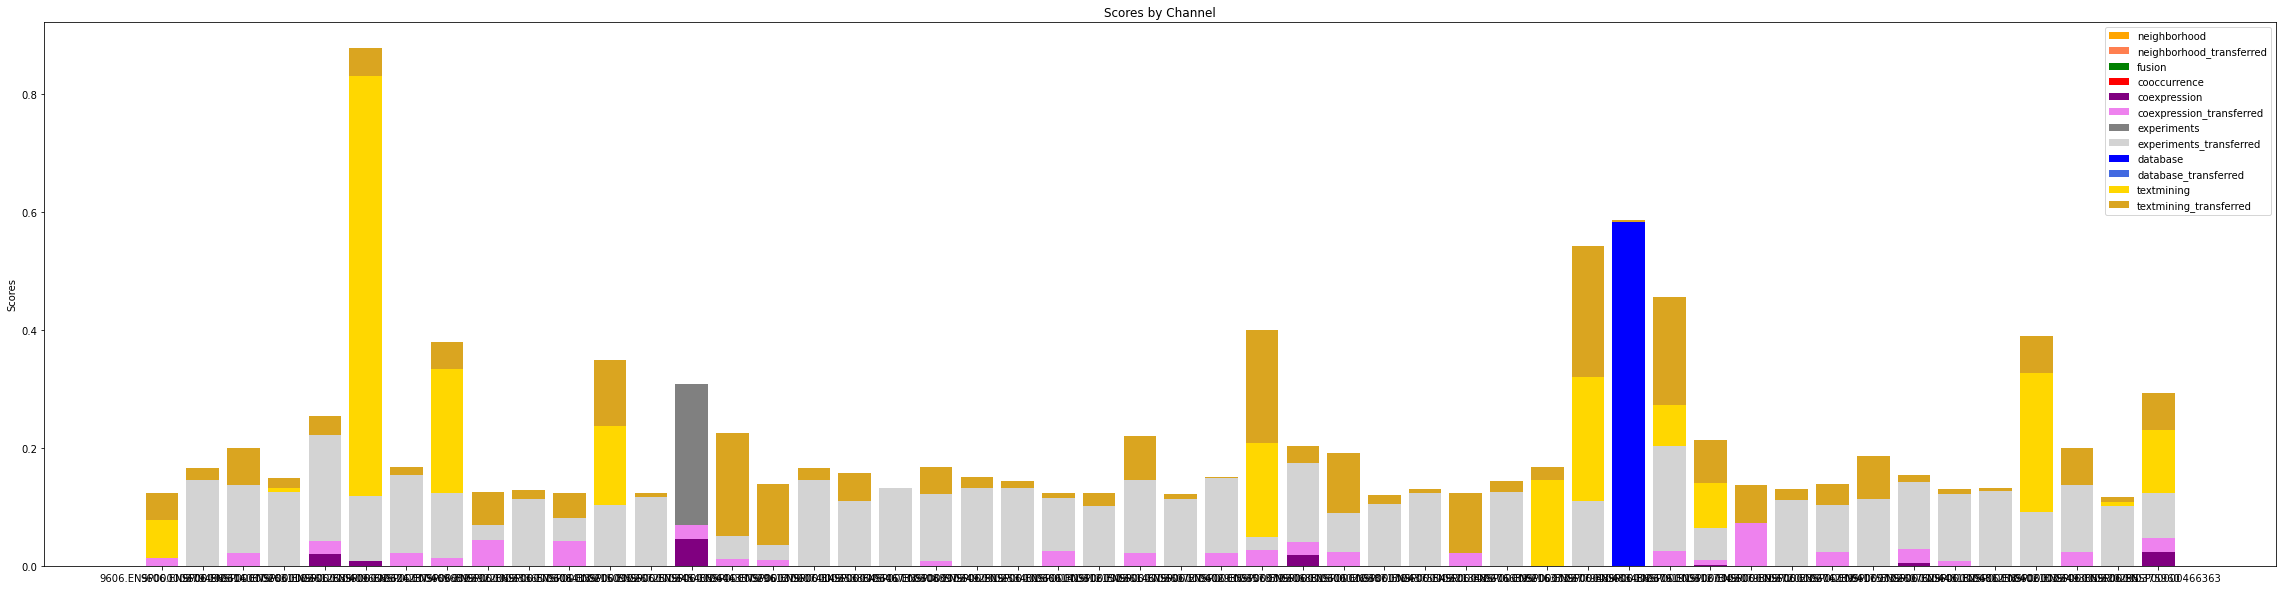

In [105]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = step2.protein2.iloc[:50]

bottom_sum = []

for i, c in enumerate(step2.columns.tolist()):
    if i == 2:
        ax.bar(labels, step2[c].iloc[:50], width, label = c, color = colors[i])
        bottom_sum = step2[c].iloc[:50]
    elif i > 2:
        ax.bar(labels, step2[c].iloc[:50], width, label = c, bottom = bottom_sum, color = colors[i])
        bottom_sum = bottom_sum + step2[c].iloc[:50]

ax.set_ylabel('Scores')
ax.set_title('Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_step2-first50-associations.png')

## STEP 3

In [80]:
s3_neighborhood_both = []
s3_cooccurrence_homology = []
s3_coexpression_both = []
s3_experiments_both = []
s3_database_both = []
# s3_textmining_both = []
s3_textmining_both_homology = []

for i in range(11938498):
    neighborhood_both_prior_corrected = 1.0 - (1.0 - s2_neighborhood[i]) * (1.0 - s2_neighborhood_transferred[i])
    coexpression_both_prior_corrected = 1.0 - (1.0 - s2_coexpression[i]) * (1.0 - s2_coexpression_transferred[i])
    experiments_both_prior_corrected = 1.0 - (1.0 - s2_experiments[i]) * (1.0 - s2_experiments_transferred[i])
    database_both_prior_corrected = 1.0 - (1.0 - s2_database[i]) * (1.0 - s2_database_transferred[i])
    textmining_both_prior_corrected = 1.0 - (1.0 - s2_textmining[i]) * (1.0 - s2_textmining_transferred[i])

    ## now, do the homology correction on cooccurrence and textmining:

    cooccurrence_prior_homology_corrected = s2_cooccurrence[i] * (1.0 - homologies[i])
    textmining_both_prior_homology_corrected = textmining_both_prior_corrected * (1.0 - homologies[i])
    
    
    s3_neighborhood_both.append(neighborhood_both_prior_corrected)
    s3_coexpression_both.append(coexpression_both_prior_corrected)
    s3_experiments_both.append(experiments_both_prior_corrected)
    s3_database_both.append(database_both_prior_corrected)
#     s3_textmining_both.append(textmining_both_prior_corrected)
    s3_cooccurrence_homology.append(cooccurrence_prior_homology_corrected)
    s3_textmining_both_homology.append(textmining_both_prior_homology_corrected)

In [82]:
step3 = pd.DataFrame({'protein1': protein1_list, 'protein2': protein2_list, 'neighborhood': s3_neighborhood_both,  
                      'cooccurrence': s3_cooccurrence_homology, 'coexpression': s3_coexpression_both, 
                      'experiments': s3_experiments_both, 
                      'database': s3_database_both, 
                      'textmining_homology': s3_textmining_both_homology})

print('neighborhood', step3.neighborhood.sum())
print('cooccurrence', step3.cooccurrence.sum())
print('coexpression', step3.coexpression.sum())
print('experiments', step3.experiments.sum())
print('database', step3.database.sum())
print('textmining_homology', step3.textmining_homology.sum())

neighborhood 22255.876955161664
cooccurrence 8304.3032721585
coexpression 497598.4689386867
experiments 646312.1006066232
database 283415.5182481753
textmining_homology 1809182.2918584351


In [120]:
width = 0.8       # the width of the bars: can also be len(x) sequence

colors = ['', '', 'orange', 'red', 'purple', 'grey', 'blue', 'gold']

fig, ax = plt.subplots(figsize=(40, 10))
labels = step3.protein2.iloc[:50]

bottom_sum = []

for i, c in enumerate(step3.columns.tolist()):
    if i == 2:
        ax.bar(labels, step3[c].iloc[:50]*1000, width, label = c, color = colors[i])
        bottom_sum = step3[c].iloc[:50]
    elif i > 2:
        ax.bar(labels, step3[c].iloc[:50]*1000, width, label = c, bottom = bottom_sum, color = colors[i])
        bottom_sum = bottom_sum + step3[c].iloc[:50]


ax.set_ylabel('Scores')
ax.set_title('Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_step3-first50-associations.png')

TypeError: float() argument must be a string or a number, not 'list'

TypeError: float() argument must be a string or a number, not 'list'

<Figure size 2880x720 with 1 Axes>

## STEP 4

In [90]:
for i in range(11938498):   
    combined_score_one_minus = (
        (1.0 - s3_neighborhood_both[i]) *
        (1.0 - s2_fusion[i]) *
        (1.0 - s3_cooccurrence_homology[i]) *
        (1.0 - s3_coexpression_both[i]) *
        (1.0 - s3_experiments_both[i]) *
        (1.0 - s3_database_both[i]) *
        (1.0 - s3_textmining_both_homology[i]) ) 
    
    step4.append(combined_score_one_minus)

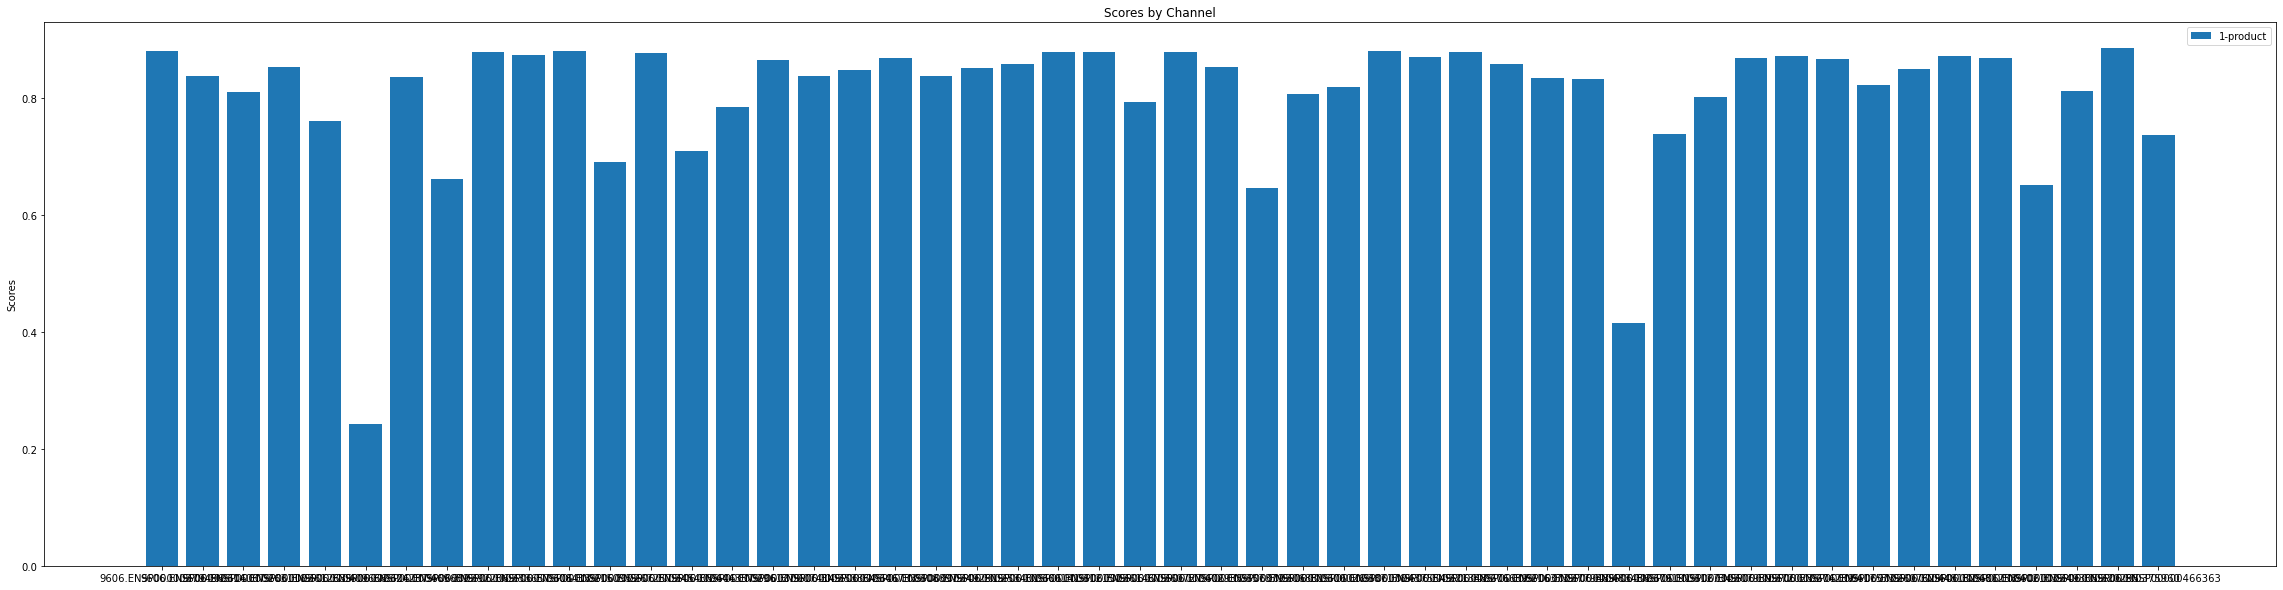

In [101]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = protein2_list[:50]

bottom_sum = []

ax.bar(labels, step4[:50], width, label = '1-product')
bottom_sum = step4[:50]


ax.set_ylabel('Scores')
ax.set_title('Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_step4-first50-associations.png')

## STEP 5

In [97]:
step5 = []
for i in range(11938498):
    combined_score = (1.0 - step4[i])            ## 1- conversion
    combined_score *= (1.0 - prior)                              ## scale down
    combined_score += prior                                      ## and add prior.

    combined_score = int(combined_score * 1000)
    step5.append(combined_score)

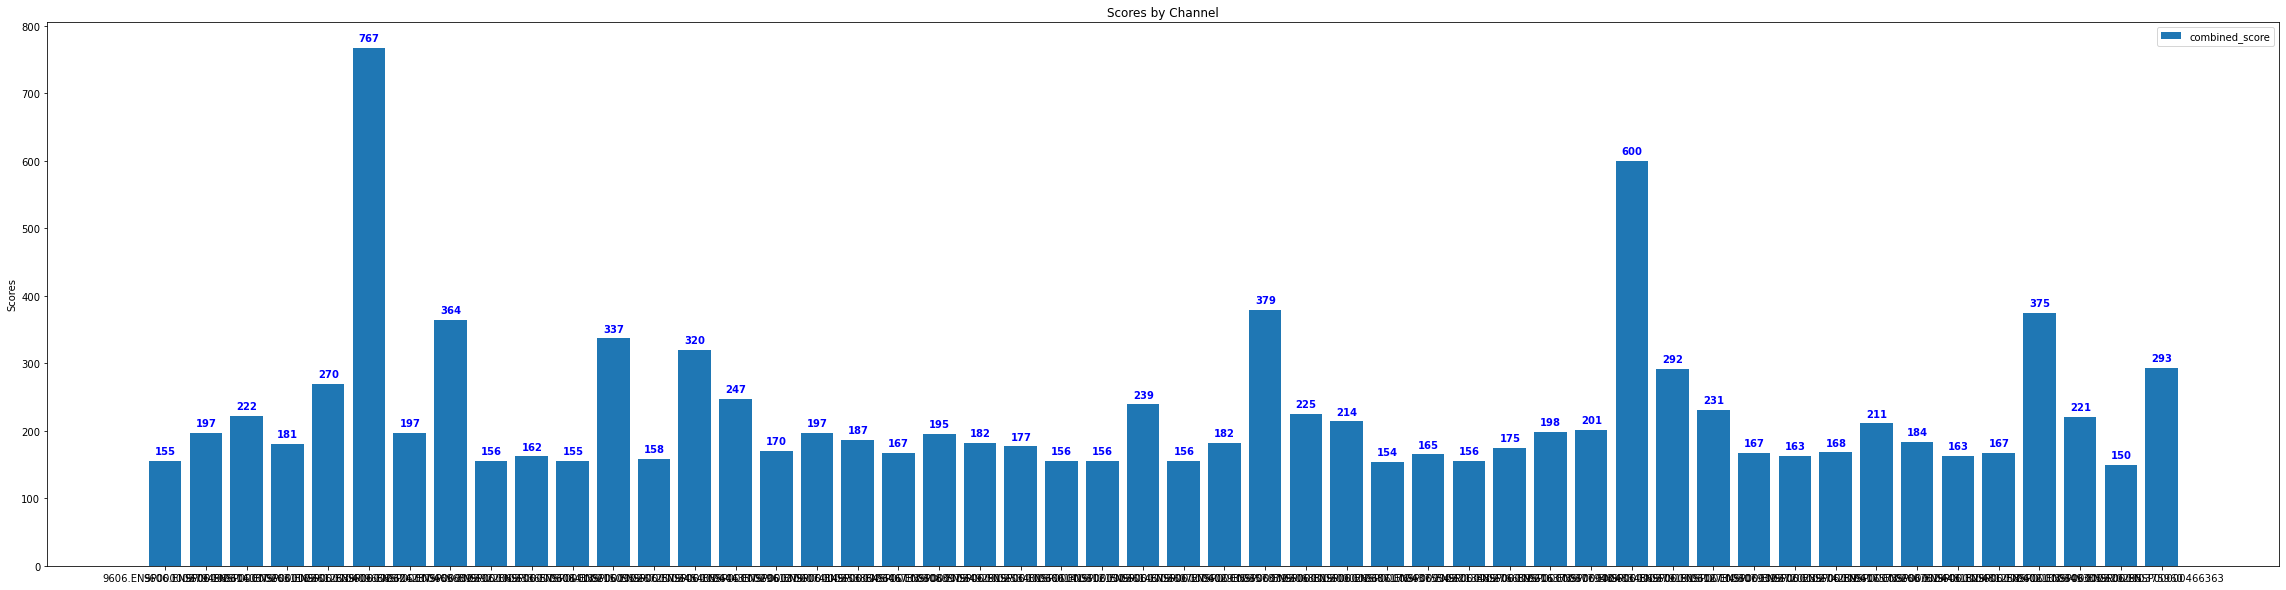

In [115]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = protein2_list[:50]

bottom_sum = []

ax.bar(labels, step5[:50], width, label = 'combined_score')
for i, v in enumerate(step5[:50]):
    ax.text(i-0.25, v + 10, str(v), color='blue', fontweight='bold')
bottom_sum = step5[:50]


ax.set_ylabel('Scores')
ax.set_title('Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_step5-first50-associations.png')

In [108]:
print(step5[:50])

[155, 197, 222, 181, 270, 767, 197, 364, 156, 162, 155, 337, 158, 320, 247, 170, 197, 187, 167, 195, 182, 177, 156, 156, 239, 156, 182, 379, 225, 214, 154, 165, 156, 175, 198, 201, 600, 292, 231, 167, 163, 168, 211, 184, 163, 167, 375, 221, 150, 293]


# GATA1

In [6]:
gata1 = pd.read_pickle('../data/GATA1_top-STRING-associations.pkl')

In [7]:
def compute_prior_away(score):
    prior = 0.041
    if score < prior: score = prior
    score_no_prior = (score - prior) / (1 - prior)

    return score_no_prior

columns = ['neighborhood', 'neighborhood_transferred', 'fusion', 'cooccurence', 'homology', 'coexpression', 
           'coexpression_transferred', 'experiments', 'experiments_transferred', 'database', 'database_transferred', 
           'textmining', 'textmining_transferred']

gata1

,protein2,neighborhood,neighborhood_transferred,fusion,cooccurence,homology,coexpression,coexpression_transferred,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,,,,,,,
9606.ENSP00000365858,9606.ENSP00000326630,0,0,0,0,0,0,0,462,694,900,0,989,101,999,GATA1,ZFPM1
9606.ENSP00000365858,9606.ENSP00000257818,0,0,0,0,0,76,161,887,117,600,0,989,209,999,GATA1,LMO2
9606.ENSP00000365858,9606.ENSP00000294339,0,0,0,0,0,174,108,500,492,600,0,989,249,999,GATA1,TAL1
9606.ENSP00000365858,9606.ENSP00000392466,0,0,0,0,0,0,0,0,245,600,0,989,148,996,GATA1,LDB1
9606.ENSP00000365858,9606.ENSP00000305918,0,0,0,0,0,0,53,800,176,0,0,978,49,996,GATA1,BRD3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000365858,9606.ENSP00000278616,0,0,0,0,0,0,0,0,0,0,0,151,0,150,GATA1,ATM
9606.ENSP00000365858,9606.ENSP00000216117,0,0,0,0,0,0,0,0,0,0,0,117,77,150,GATA1,HMOX1
9606.ENSP00000365858,9606.ENSP00000351520,0,0,0,0,0,0,0,0,0,0,0,125,69,150,GATA1,ENTPD4


0 neighborhood
1 neighborhood_transferred
2 fusion
3 cooccurence
4 homology
homology
5 coexpression
6 coexpression_transferred
7 experiments
8 experiments_transferred
9 database
10 database_transferred
11 textmining
12 textmining_transferred


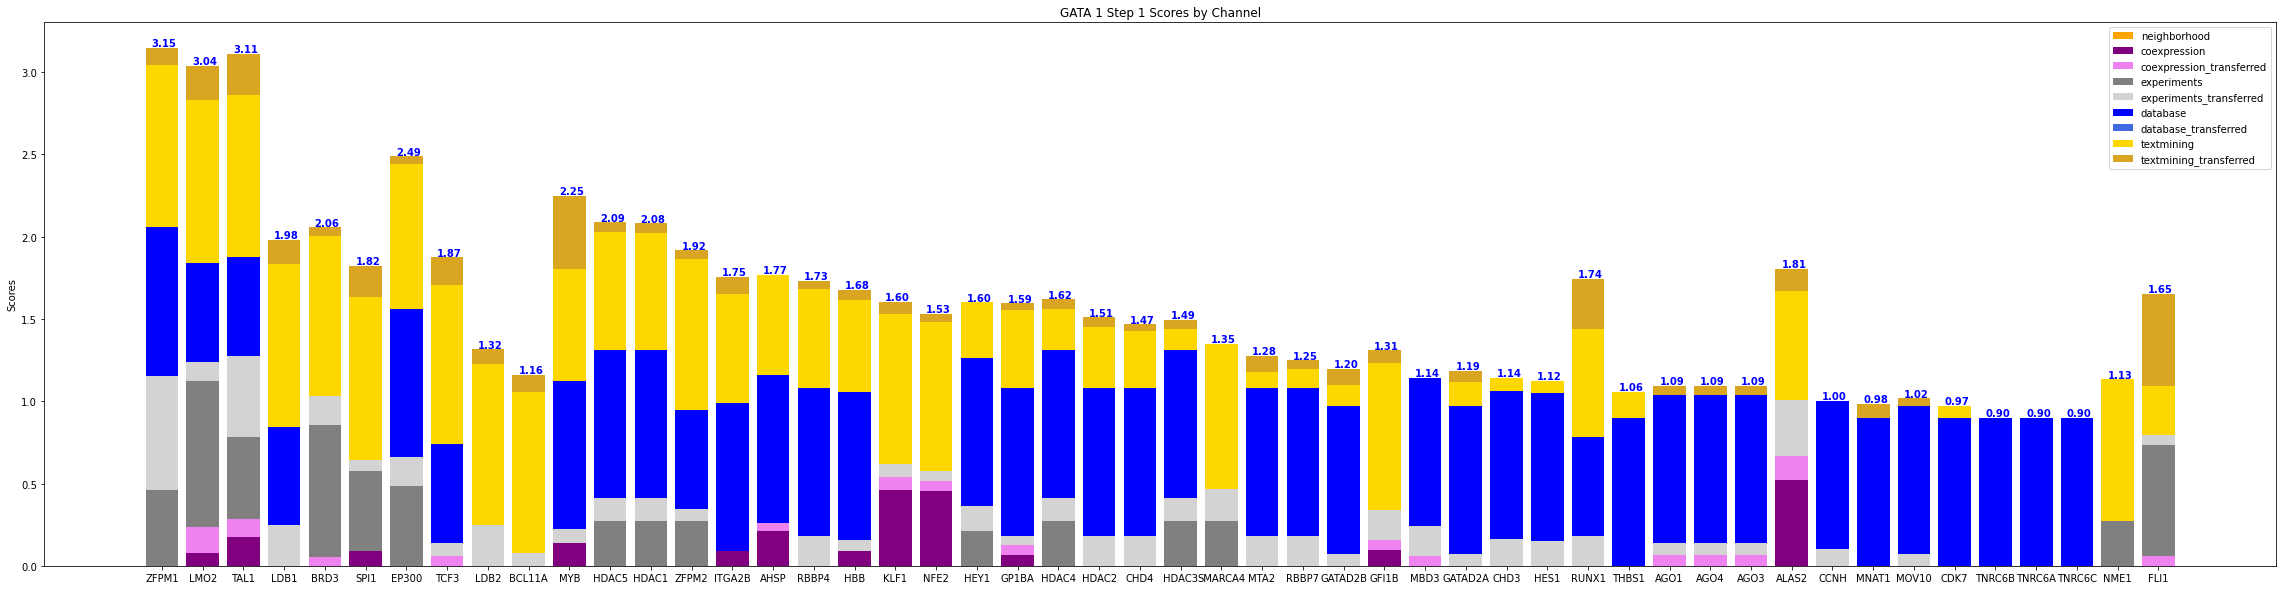

In [10]:
    
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = gata1['protein2_pref'][:50]

colors = ['orange', 'coral', 'green', 'red', 'purple', 'violet', 'grey', 'lightgrey', 'blue', 'royalblue', 'gold', 'goldenrod']

bottom_sum = []

for i, c in enumerate(columns):
    print(i, c)
    gata1['s1_'+c] = gata1[c]/1000
    if i == 0:
        ax.bar(labels, gata1['s1_'+ c].iloc[:50], width, label = c, color = colors[i])
        bottom_sum = gata1['s1_'+c].iloc[:50]
    elif c == 'homology':
        print('homology')
        continue
    elif i > 3:
        ax.bar(labels, gata1['s1_' + c].iloc[:50], width, label = c, bottom = bottom_sum, color = colors[i-1])
        bottom_sum = bottom_sum + gata1['s1_'+c].iloc[:50]

        
for i, v in enumerate(np.array(bottom_sum[:50])):
    ax.text(i-0.25, v+0.01, "{:.2f}".format(v), color='blue', fontweight='bold')

ax.set_ylabel('Scores')
ax.set_title('GATA 1 Step 1 Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_GATA1-step1-first50-associations.png')

0 neighborhood
1 neighborhood_transferred
2 fusion
3 cooccurence
4 homology
5 coexpression
6 coexpression_transferred
7 experiments
8 experiments_transferred
9 database
10 database_transferred
11 textmining
12 textmining_transferred


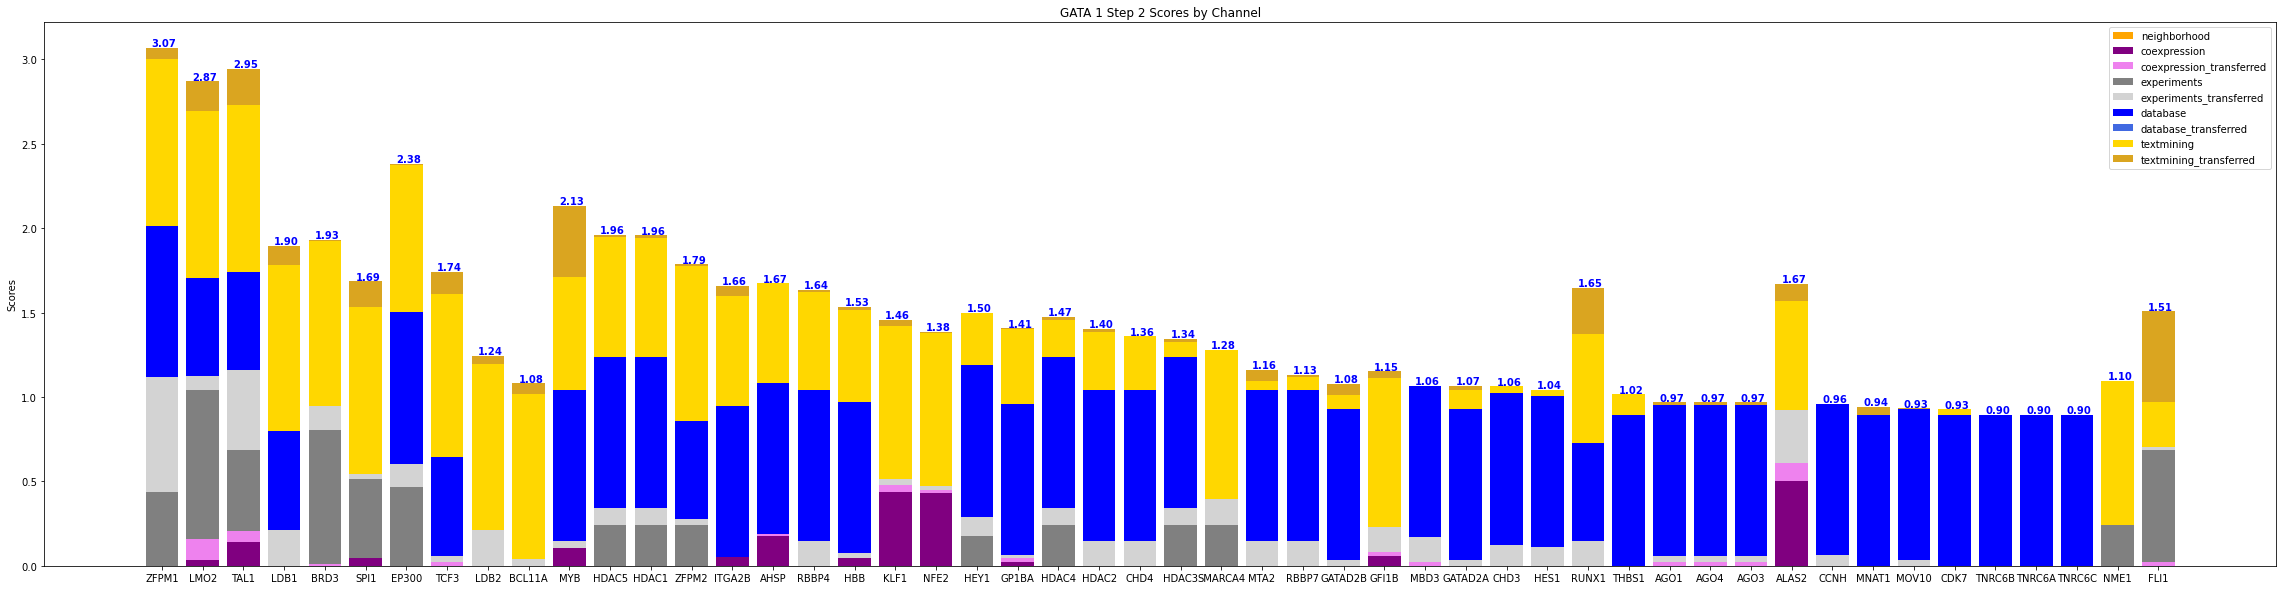

In [12]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = gata1['protein2_pref'][:50]

colors = ['orange', 'coral', 'green', 'red', 'purple', 'violet', 'grey', 'lightgrey', 'blue', 'royalblue', 'gold', 'goldenrod']

bottom_sum = []

for i, c in enumerate(columns):
    print(i, c)
    gata1['s2_'+c] = gata1['s1_'+c].map(compute_prior_away)
    if i == 0:
        ax.bar(labels, gata1['s2_'+ c].iloc[:50], width, label = c, color = colors[i])
        bottom_sum = gata1['s2_'+c].iloc[:50]
    elif c == 'homology':
        continue
    elif i > 3:
        ax.bar(labels, gata1['s2_' + c].iloc[:50], width, label = c, bottom = bottom_sum, color = colors[i-1])
        bottom_sum = bottom_sum + gata1['s2_'+c].iloc[:50]

for i, v in enumerate(np.array(bottom_sum[:50])):
    ax.text(i-0.25, v+0.01, "{:.2f}".format(v), color='blue', fontweight='bold')
        
        
ax.set_ylabel('Scores')
ax.set_title('GATA 1 Step 2 Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_GATA1-step2-first50-associations.png')

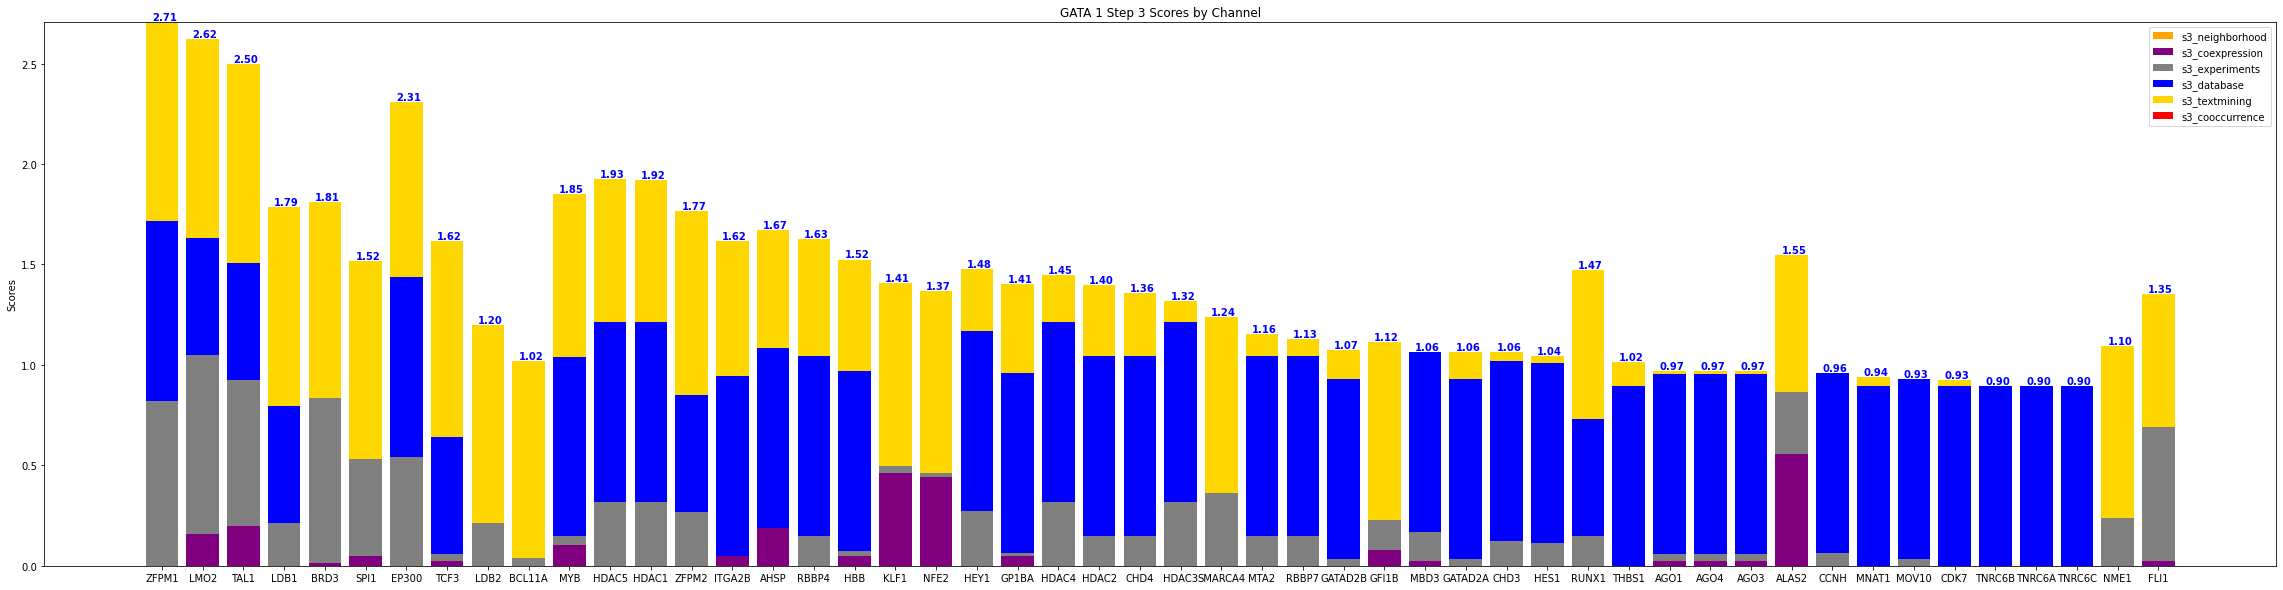

In [13]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = gata1['protein2_pref'][:50]

bottom_sum = []

colors = ['orange', 'purple', 'grey', 'blue', 'gold', 'red']

gata1['s3_neighborhood'] = 1.0-(1.0-gata1['s2_neighborhood']).multiply((1.0-gata1['s2_neighborhood_transferred']))
ax.bar(labels, gata1['s3_neighborhood'].iloc[:50], width, label = 's3_neighborhood', color = colors[0])
bottom_sum = gata1['s3_neighborhood'].iloc[:50]

gata1['s3_coexpression'] = 1.0-(1.0-gata1['s2_coexpression']).multiply((1.0-gata1['s2_coexpression_transferred']))
ax.bar(labels, gata1['s3_coexpression'].iloc[:50], width, label = 's3_coexpression', bottom = bottom_sum, color = colors[1])
bottom_sum = bottom_sum + gata1['s3_coexpression'].iloc[:50]

gata1['s3_experiments'] = 1.0-(1.0-gata1['s2_experiments']).multiply((1.0-gata1['s2_experiments_transferred']))
ax.bar(labels, gata1['s3_experiments'].iloc[:50], width, label = 's3_experiments', bottom = bottom_sum, color = colors[2])
bottom_sum = bottom_sum + gata1['s3_experiments'].iloc[:50]

gata1['s3_database'] = 1.0-(1.0-gata1['s2_database']).multiply((1.0-gata1['s2_database_transferred']))
ax.bar(labels, gata1['s3_database'].iloc[:50], width, label = 's3_database', bottom = bottom_sum, color = colors[3])
bottom_sum = bottom_sum + gata1['s3_database'].iloc[:50]
    
gata1['s3_textmining'] = 1.0-(1.0-gata1['s2_textmining']).multiply((1.0-gata1['s2_textmining_transferred']))


# Homology correction
gata1['s3_textmining_homology'] = gata1['s3_textmining'] * (1.0-gata1['homology'])
ax.bar(labels, gata1['s3_textmining'].iloc[:50], width, label = 's3_textmining', bottom = bottom_sum, color = colors[4])
bottom_sum = bottom_sum + gata1['s3_textmining_homology'].iloc[:50]
    
gata1['s3_cooccurrence'] = gata1['s2_cooccurence'] * (1.0-gata1['homology'])
ax.bar(labels, gata1['s3_cooccurrence'].iloc[:50], width, label = 's3_cooccurrence', bottom = bottom_sum, color = colors[5])
bottom_sum = bottom_sum + gata1['s3_cooccurrence'].iloc[:50]

# print(bottom_sum)

for i, v in enumerate(np.array(bottom_sum[:50])):
    ax.text(i-0.25, v+0.01, "{:.2f}".format(v), color='blue', fontweight='bold')

ax.set_ylabel('Scores')
ax.set_title('GATA 1 Step 3 Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_GATA1-step3-first50-associations.png')

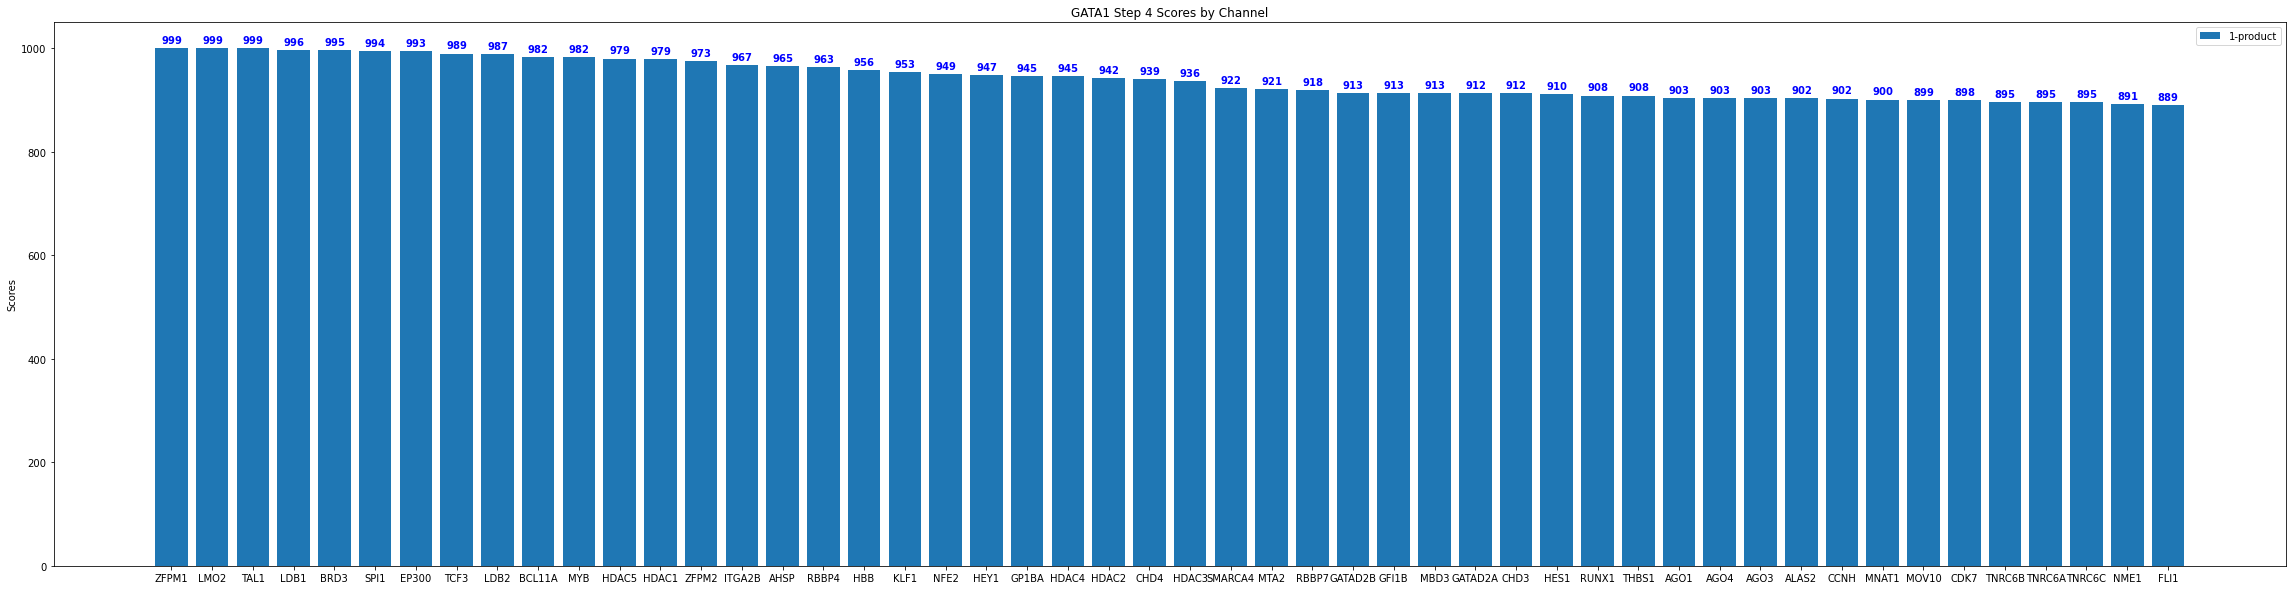

In [14]:
product = (1.0 - gata1['s3_neighborhood']) * (1.0-gata1['s2_fusion']) * (1.0 - gata1['s3_coexpression']) * (1.0 - gata1['s3_experiments']) * (1.0 - gata1['s3_database']) * (1.0 - gata1['s3_textmining_homology']) * (1.0 - gata1['s3_cooccurrence'])

gata1['s4'] = 1.0-product

width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = gata1['protein2_pref'][:50]

bottom_sum = []

ax.bar(labels, gata1['s4'][:50]*1000, width, label = '1-product')
for i, v in enumerate(gata1['s4'][:50]*1000):
    ax.text(i-0.25, v+10, str(int(v)), color='blue', fontweight='bold')
bottom_sum = gata1['s4'][:50]


ax.set_ylabel('Scores')
ax.set_title('GATA1 Step 4 Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_GATA1-step4-first50-associations.png')

In [15]:
gata1['s5'] = ((gata1['s4'] * (1.0 - prior)) + prior) * 1000          ## 1- conversion

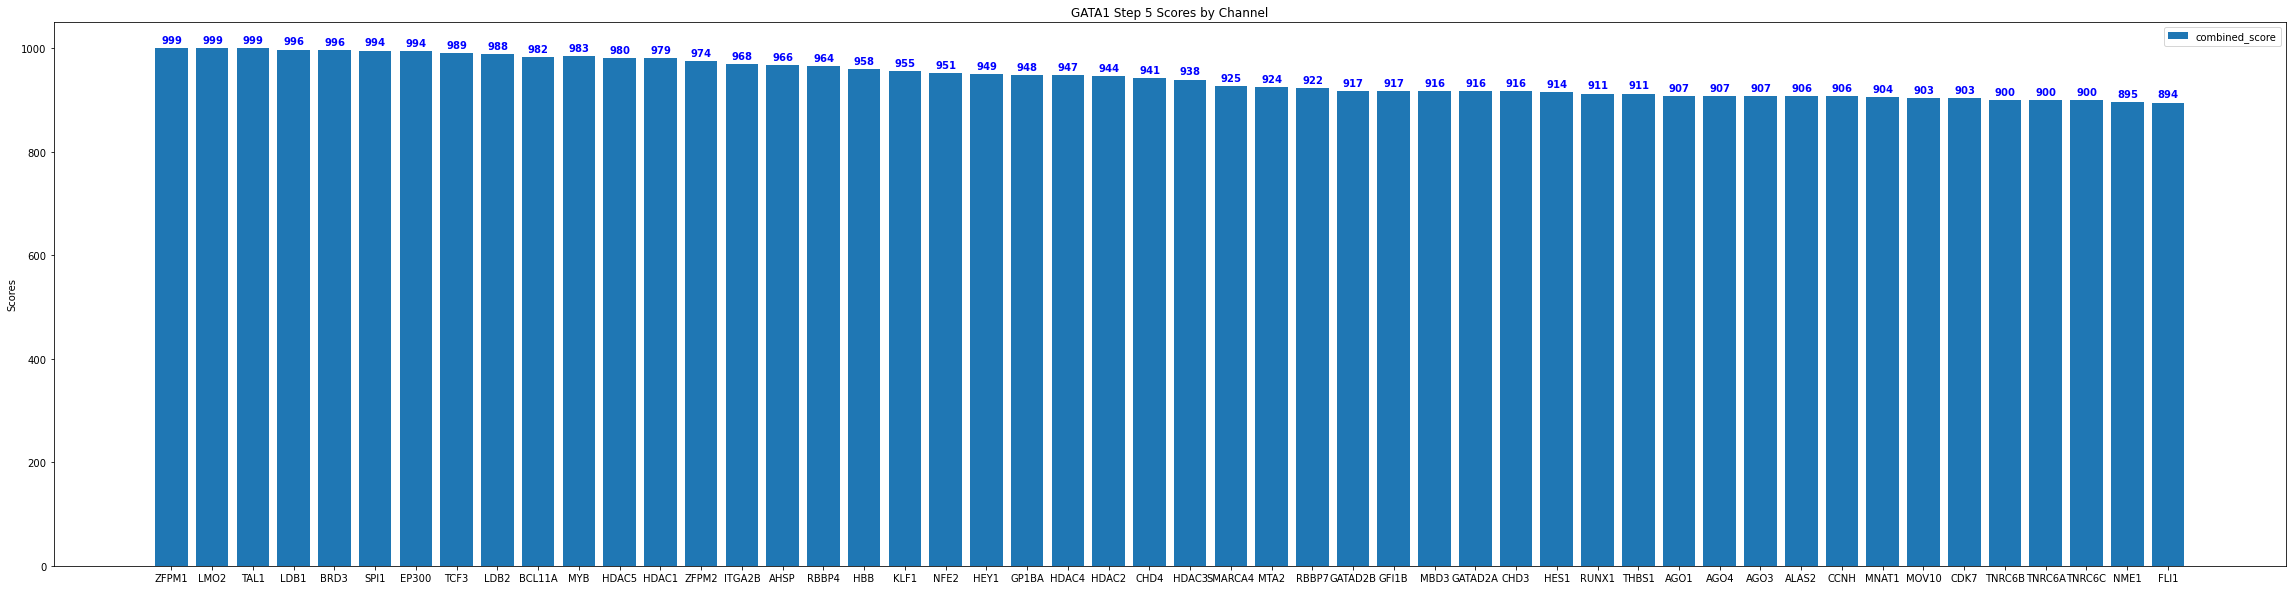

In [16]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = gata1['protein2_pref'][:50]

bottom_sum = []

ax.bar(labels, gata1['s5'][:50], width, label = 'combined_score')
for i, v in enumerate(gata1['s5'][:50]):
    ax.text(i-0.25, v+10, str(int(v)), color='blue', fontweight='bold')
bottom_sum = gata1['s5'][:50]


ax.set_ylabel('Scores')
ax.set_title('GATA1 Step 5 Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_GATA1-step5-first50-associations.png')

# Fraction Plotting for GATA1

In [14]:
columns = ['neighborhood', 'fusion', 'cooccurence', 'coexpression', 'experimental', 'database', 'textmining']

In [10]:
gata1_individual_scores = pd.read_pickle('../data/GATA1_top-STRING-associations-s3-individual.pkl')

In [11]:
gata1_individual_scores

,protein2,neighborhood,fusion,cooccurence,coexpression,experimental,database,textmining,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,
9606.ENSP00000365858,9606.ENSP00000326630,0,0,0,0,828,900,990,999,GATA1,ZFPM1
9606.ENSP00000365858,9606.ENSP00000257818,0,0,0,192,896,600,991,999,GATA1,LMO2
9606.ENSP00000365858,9606.ENSP00000294339,0,0,0,232,735,600,991,999,GATA1,TAL1
9606.ENSP00000365858,9606.ENSP00000392466,0,0,0,0,245,600,990,996,GATA1,LDB1
9606.ENSP00000365858,9606.ENSP00000305918,0,0,0,53,828,0,978,996,GATA1,BRD3
...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000365858,9606.ENSP00000278616,0,0,0,0,0,0,151,150,GATA1,ATM
9606.ENSP00000365858,9606.ENSP00000216117,0,0,0,0,0,0,150,150,GATA1,HMOX1
9606.ENSP00000365858,9606.ENSP00000351520,0,0,0,0,0,0,151,150,GATA1,ENTPD4


In [36]:
gata1_individual_scores['total'] = gata1_individual_scores[columns].sum(axis=1)
print(gata1_individual_scores['total'])

for c in columns:
    gata1_individual_scores[c+'_fraction'] = gata1_individual_scores[c].divide(gata1_individual_scores['total'])

protein1
9606.ENSP00000365858    2718
9606.ENSP00000365858    2679
9606.ENSP00000365858    2558
9606.ENSP00000365858    1835
9606.ENSP00000365858    1859
                        ... 
9606.ENSP00000365858     151
9606.ENSP00000365858     150
9606.ENSP00000365858     151
9606.ENSP00000365858     151
9606.ENSP00000365858     192
Name: total, Length: 1746, dtype: int64


0 neighborhood
1 fusion
2 cooccurence
3 coexpression
4 experimental
5 database
6 textmining


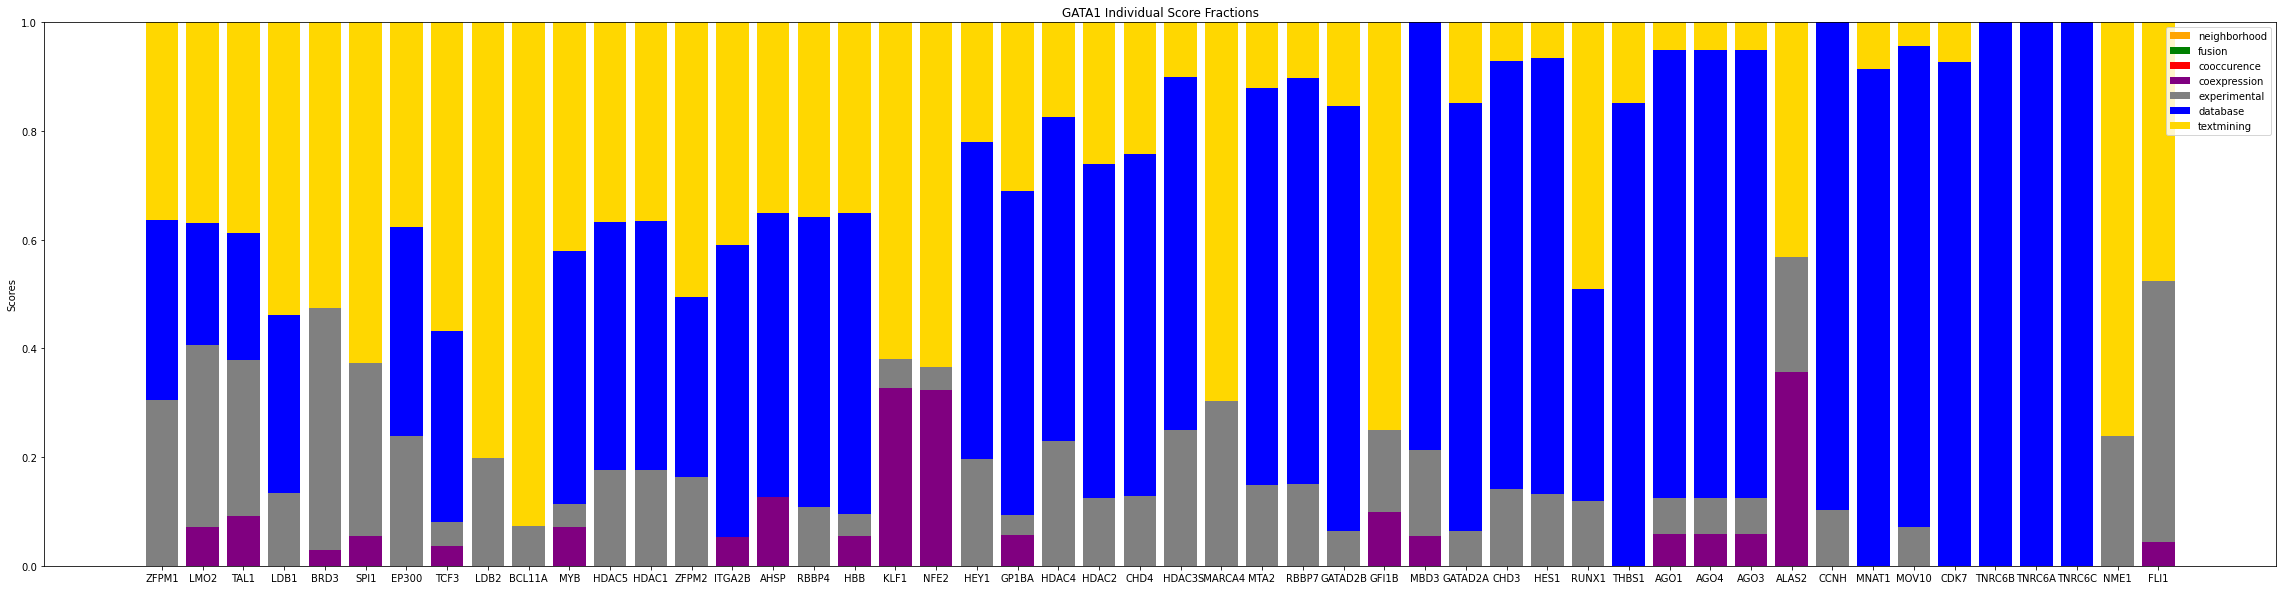

In [37]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = gata1_individual_scores['protein2_pref'][:50]

colors = ['orange', 'green', 'red', 'purple', 'grey', 'blue', 'gold']

bottom_sum = []

for i, c in enumerate(columns):
    print(i, c)
    if i == 0:
        ax.bar(labels, gata1_individual_scores[c + '_fraction'].iloc[:50], width, label = c, color = colors[i])
        bottom_sum = gata1_individual_scores[c + '_fraction'].iloc[:50]
    else:
        ax.bar(labels, gata1_individual_scores[c + '_fraction'].iloc[:50], width, label = c, bottom = bottom_sum, color = colors[i])
        bottom_sum = bottom_sum + gata1_individual_scores[c + '_fraction'].iloc[:50]

# for i, v in enumerate(np.array(bottom_sum[:50])):
#     ax.text(i-0.25, v-0.01, "{:.2f}".format(v), color='blue', fontweight='bold')
        
        
ax.set_ylabel('Scores')
ax.set_title('GATA1 Individual Score Fractions')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_GATA1-individual-outof100-first50-associations.png')

In [38]:
for c in columns:
    gata1_individual_scores[c+'_fraction'] = gata1_individual_scores[c].divide(gata1_individual_scores['total']).multiply(gata1_individual_scores['combined_score'])

0 neighborhood
1 fusion
2 cooccurence
3 coexpression
4 experimental
5 database
6 textmining


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/IPython/core/pylabtools.py:137: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


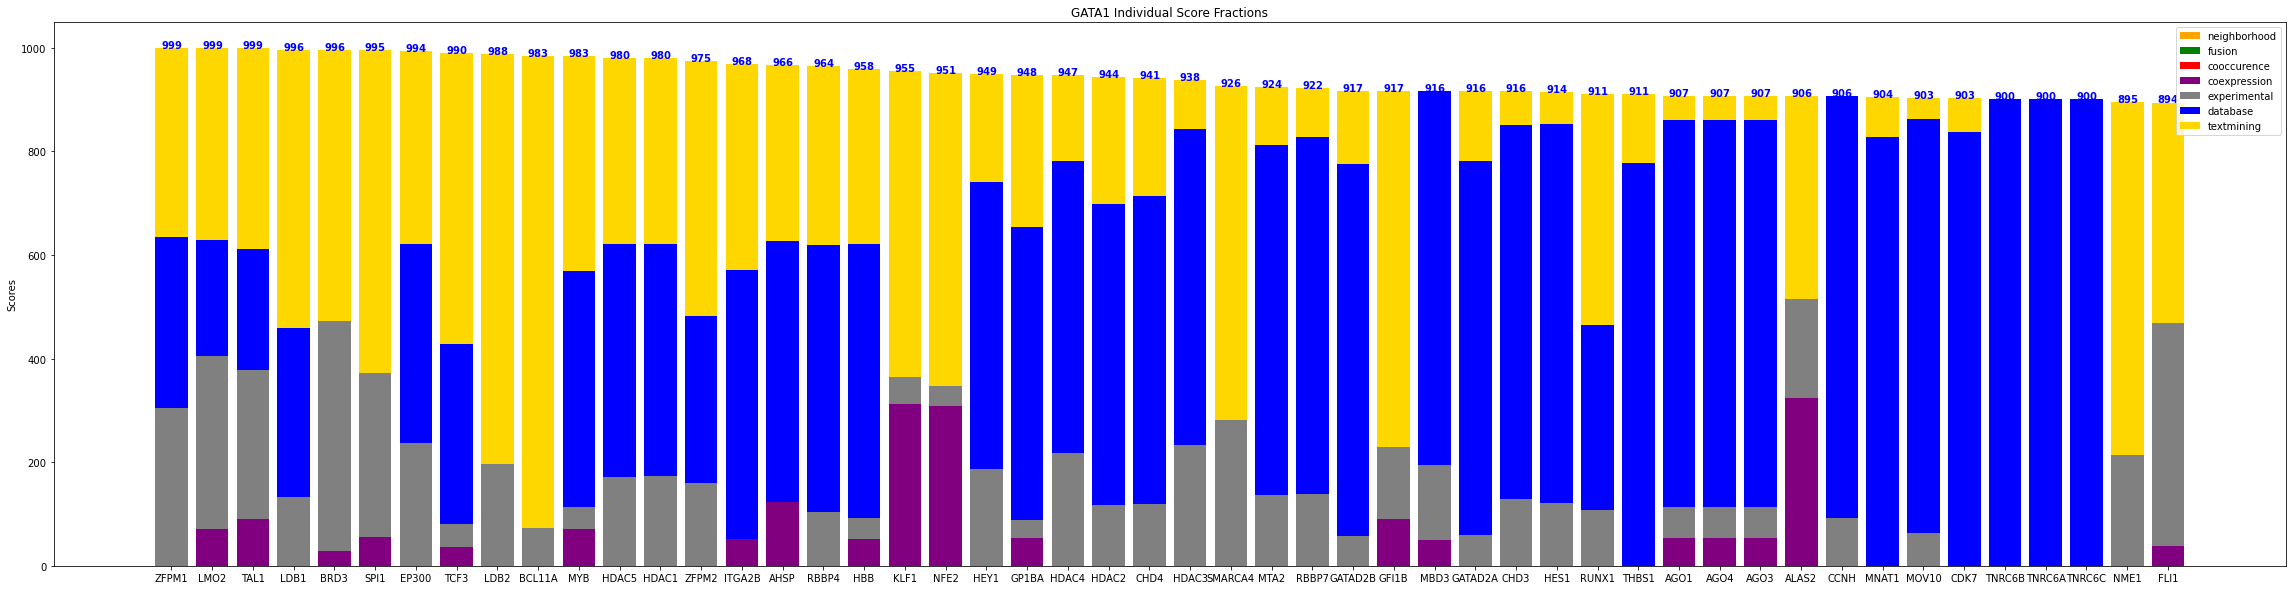

In [39]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = gata1_individual_scores['protein2_pref'][:50]

colors = ['orange', 'green', 'red', 'purple', 'grey', 'blue', 'gold']

bottom_sum = []

for i, c in enumerate(columns):
    print(i, c)
    if i == 0:
        ax.bar(labels, gata1_individual_scores[c + '_fraction'].iloc[:50], width, label = c, color = colors[i])
        bottom_sum = gata1_individual_scores[c + '_fraction'].iloc[:50]
    else:
        ax.bar(labels, gata1_individual_scores[c + '_fraction'].iloc[:50], width, label = c, bottom = bottom_sum, color = colors[i])
        bottom_sum = bottom_sum + gata1_individual_scores[c + '_fraction'].iloc[:50]

for i, v in enumerate(np.array(bottom_sum[:50])):
    ax.text(i-0.25, v+0.02, "{:.0f}".format(v), color='blue', fontweight='bold')
        
        
ax.set_ylabel('Scores')
ax.set_title('GATA1 Individual Score Fractions')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_GATA1-individual-outofcombined-first50-associations.png')